In [2]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )

Df_DA=df[df['job_title_short']=='Data Analyst'].copy()

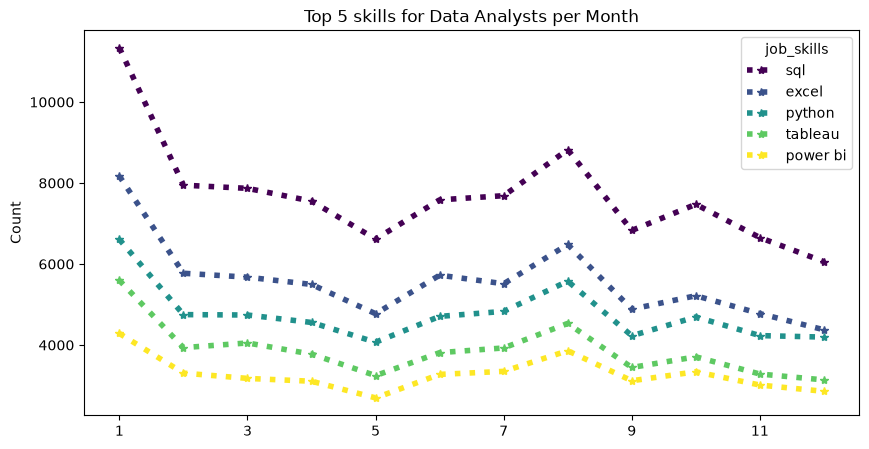

In [3]:
Df_DA['job_posted_month_no']=Df_DA['job_posted_date'].dt.month
Df_DA_explode=Df_DA.explode('job_skills')
Df_DA_explode_pivot=Df_DA_explode.pivot_table(index='job_posted_month_no',columns='job_skills',aggfunc='size',fill_value=0)
Df_DA_explode_pivot.loc['Total']=Df_DA_explode_pivot.sum()
Df_DA_top_skills=Df_DA_explode_pivot[Df_DA_explode_pivot.loc['Total'].sort_values(ascending=False).index]
Df_DA_top_skills=Df_DA_top_skills.drop('Total')
Df_DA_top_skills.iloc[:,:5].plot(kind='line',linewidth=4,linestyle=':',#options:'-','--','-.',':',
                                 colormap='viridis',
                                 marker='*',#options:'o','x','+','*'.'S',',','.','1','2','3','4',...
                                 markersize=6,
                                 figsize=(10,5))
plt.title('Top 5 skills for Data Analysts per Month')
plt.ylabel('Count')
plt.xlabel('')
plt.show()



In [4]:
Df_DA_explode=Df_DA.explode('job_skills')

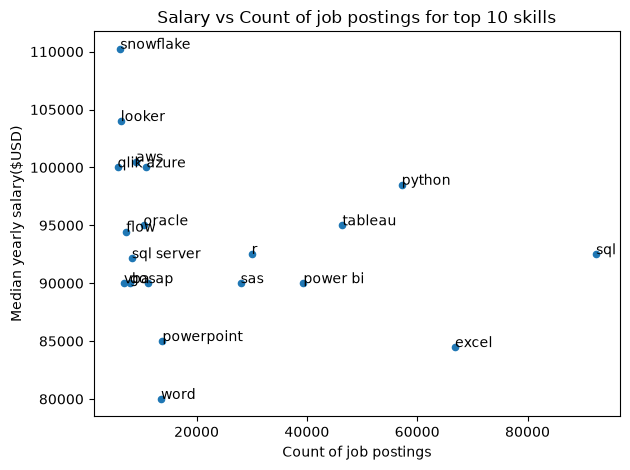

In [5]:
skill_stats=Df_DA_explode.groupby('job_skills').agg(
    skill_count=('job_skills','count'), 
    median_salary=('salary_year_avg','median')

)

skill_count=20
skill_stats=skill_stats.sort_values(by='skill_count',ascending=False).head(skill_count)

skill_stats.plot(kind='scatter',x='skill_count',y='median_salary')
plt.xlabel('Count of job postings')
plt.ylabel('Median yearly salary($USD)')
plt.title('Salary vs Count of job postings for top 10 skills')
plt.tight_layout()

for i,txt in enumerate(skill_stats.index):
    plt.text(skill_stats['skill_count'].iloc[i],skill_stats['median_salary'].iloc[i],txt)
plt.show()


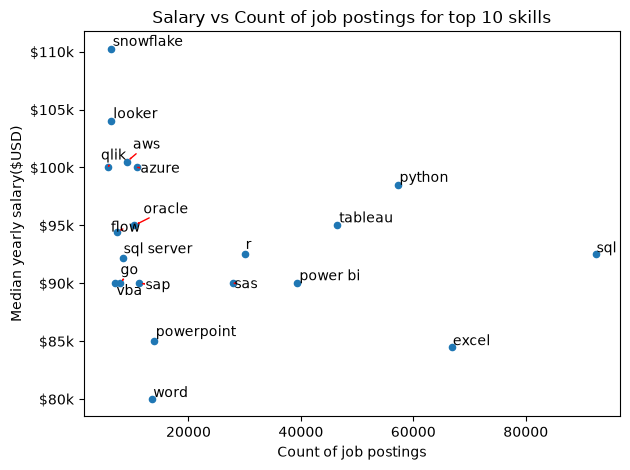

In [ ]:
# inserted comma in x axis using chatgpt
from adjustText import adjust_text 

# fig,ax=plt.subplots()

skill_stats=Df_DA_explode.groupby('job_skills').agg(
    skill_count=('job_skills','count'), 
    median_salary=('salary_year_avg','median')

)

skill_count=20
skill_stats=skill_stats.sort_values(by='skill_count',ascending=False).head(skill_count)

skill_stats.plot(kind='scatter',x='skill_count',y='median_salary')
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos:f'${int(y/1000)}k'))
plt.xlabel('Count of job postings')
plt.ylabel('Median yearly salary($USD)')
plt.title('Salary vs Count of job postings for top 10 skills')
plt.tight_layout()

texts=[]
for i,txt in enumerate(skill_stats.index):
    texts.append(plt.text(skill_stats['skill_count'].iloc[i],skill_stats['median_salary'].iloc[i],txt))

adjust_text(texts,arrowprops=dict(arrowstyle='->',color='red'))
plt.show()


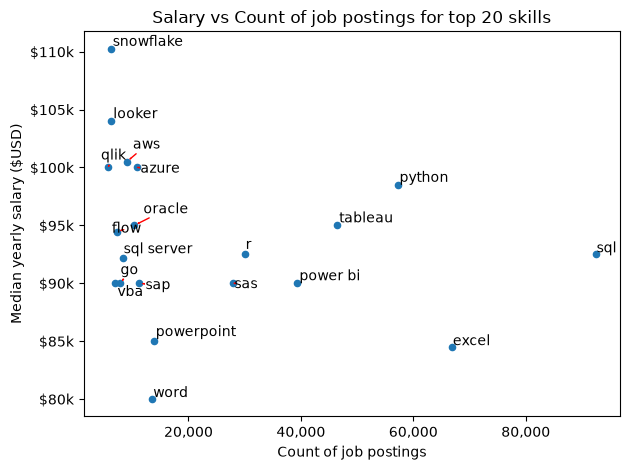

In [17]:
from adjustText import adjust_text 

skill_stats = Df_DA_explode.groupby('job_skills').agg(
    skill_count=('job_skills', 'count'), 
    median_salary=('salary_year_avg', 'median')
)

skill_count = 20
skill_stats = skill_stats.sort_values(
    by='skill_count', 
    ascending=False
).head(skill_count)

skill_stats.plot(
    kind='scatter',
    x='skill_count',
    y='median_salary'
)

ax = plt.gca()

# X-axis: add commas
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{int(x):,}')
)

# Y-axis: show salary as $XXk
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}k')
)

plt.xlabel('Count of job postings')
plt.ylabel('Median yearly salary ($USD)')
plt.title('Salary vs Count of job postings for top 20 skills')
plt.tight_layout()

texts = []

for i, txt in enumerate(skill_stats.index):
    texts.append(
        plt.text(
            skill_stats['skill_count'].iloc[i],
            skill_stats['median_salary'].iloc[i],
            txt
        )
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='->', color='red')
)

plt.show()